In [20]:
print("Commodity Market Analysis")
print("My first quantitative research project!")

Commodity Market Analysis
My first quantitative research project!


# Commodity Market Analysis & Trading Strategy Backtest

## Objective
Analyze historical gold and crude oil futures price series to compare market performance and risk, then evaluate a simple moving-average trend-following strategy against a buy-and-hold benchmark.

## Research questions
- How did gold and crude oil differ in historical returns and volatility?
- What drawdowns did each market experience?
- Did a 20-day/50-day moving-average strategy improve historical risk-adjusted performance in crude oil?
- How consistent were the strategy's results across different periods?

## Methodology
Historical daily price data were retrieved using Yahoo Finance. Python, pandas, NumPy and matplotlib were used for data processing, return calculations, risk metrics, visualization and backtesting.

The strategy uses a 20-day and 50-day moving-average crossover, with a one-day signal shift and an assumed transaction cost of 0.05% per position change. Its results are compared with a buy-and-hold benchmark.

## Important limitations
The analysis uses continuous-futures price series, which may not represent returns achievable from trading individual futures contracts. The backtest uses simplified execution and cost assumptions, and its results are historical rather than predictive. The apparent performance improvement requires further out-of-sample testing and robustness checks.

In [21]:
%pip install yfinance pandas matplotlib

In [22]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

tickers = {
    "Gold": "GC=F",
    "Crude Oil": "CL=F"
}

data = yf.download(
    list(tickers.values()),
    period="5y",
    auto_adjust=False
)

print(data.tail())

[*********************100%***********************]  2 of 2 completed

Price        Adj Close                    Close                     High  \
Ticker            CL=F         GC=F        CL=F         GC=F        CL=F   
Date                                                                       
2026-10-14   95.089996  4107.899902   95.089996  4107.899902   96.059998   
2026-10-15   97.970001  4170.100098   97.970001  4170.100098   98.320000   
2026-10-16  101.410004  4181.100098  101.410004  4181.100098  101.900002   
2026-10-19  103.660004  4160.100098  103.660004  4160.100098  104.180000   
2026-10-20   97.389999  4152.399902   97.389999  4152.399902  101.370003   

Price                          Low                     Open               \
Ticker             GC=F       CL=F         GC=F        CL=F         GC=F   
Date                                                                       
2026-10-14  4193.500000  93.970001  4095.000000   94.750000  4184.200195   
2026-10-15  4197.700195  93.580002  4120.899902   95.190002  4128.299805   
2026-10-16 

In [23]:
# Extract the closing prices for both commodities
prices = data["Close"].copy()

# Give the columns simpler names
prices = prices.rename(columns={
    "GC=F": "Gold",
    "CL=F": "Crude Oil"
})

# Remove rows where either price is missing
prices = prices.dropna()

print(prices.head())
print("\nDataset shape:", prices.shape)
print("\nMissing values:\n", prices.isnull().sum())

Ticker      Crude Oil         Gold
Date                              
2021-10-20  83.870003  1784.900024
2021-10-21  82.500000  1781.900024
2021-10-22  83.760002  1796.300049
2021-10-25  83.760002  1806.800049
2021-10-26  84.650002  1793.400024

Dataset shape: (1257, 2)

Missing values:
 Ticker
Crude Oil    0
Gold         0
dtype: int64


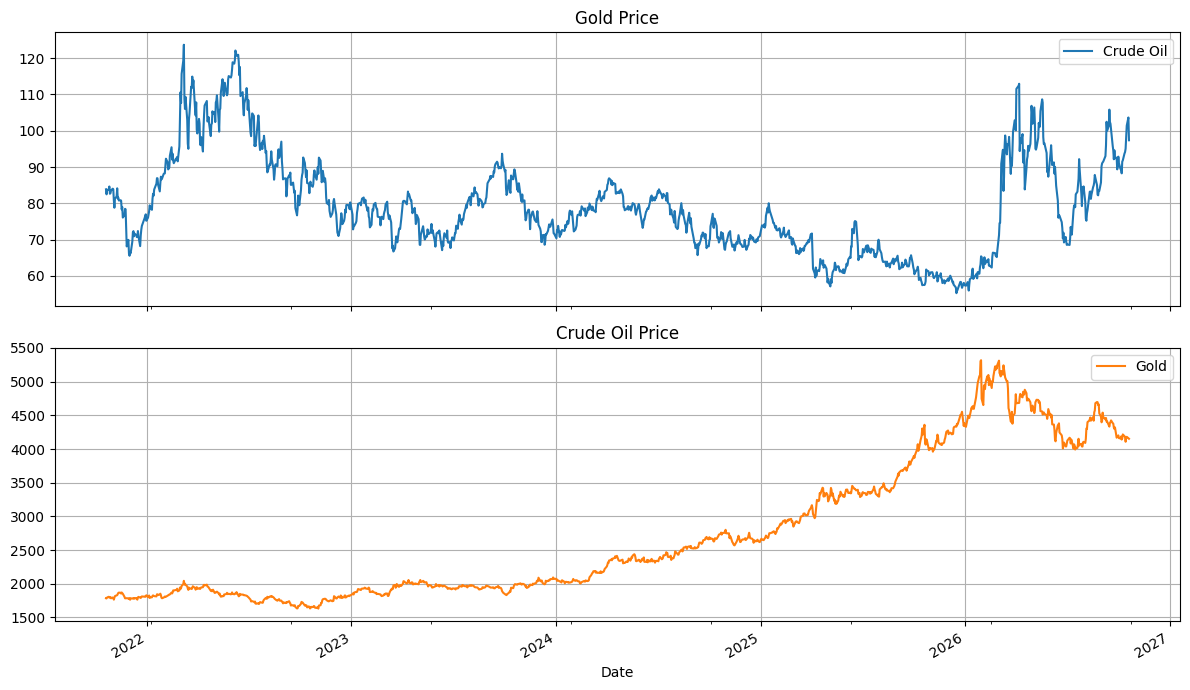

In [24]:
prices.plot(
    subplots=True,
    figsize=(12, 7),
    title=["Gold Price", "Crude Oil Price"],
    grid=True
)

plt.tight_layout()
plt.show()

In [25]:
# Daily percentage change in closing prices
returns = prices.pct_change().dropna()

print(returns.head())

Ticker      Crude Oil      Gold
Date                           
2021-10-21  -0.016335 -0.001681
2021-10-22   0.015273  0.008081
2021-10-25   0.000000  0.005845
2021-10-26   0.010626 -0.007416
2021-10-27  -0.023509  0.003011


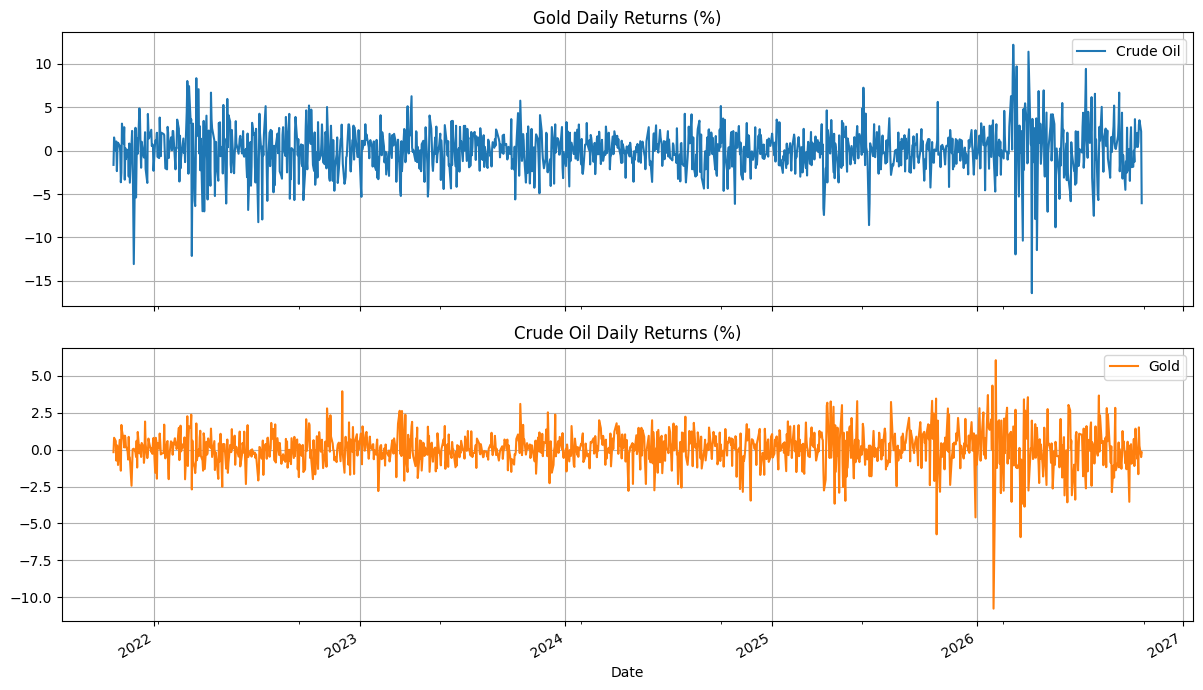

In [26]:
(returns * 100).plot(
    subplots=True,
    figsize=(12, 7),
    title=["Gold Daily Returns (%)", "Crude Oil Daily Returns (%)"],
    grid=True
)

plt.tight_layout()
plt.show()

In [27]:
import numpy as np

# Annualized return using the first and last observed prices
years = (prices.index[-1] - prices.index[0]).days / 365.25

annualized_return = (
    (prices.iloc[-1] / prices.iloc[0]) ** (1 / years) - 1
) * 100

# Annualized volatility from daily percentage returns
annualized_volatility = returns.std() * np.sqrt(252) * 100

# Maximum drawdown from each asset's running price peak
running_peak = prices.cummax()
drawdown = (prices / running_peak) - 1
maximum_drawdown = drawdown.min() * 100

# Combine results into one table
metrics = pd.DataFrame({
    "Annualized Return (%)": annualized_return,
    "Annualized Volatility (%)": annualized_volatility,
    "Maximum Drawdown (%)": maximum_drawdown
})

print(metrics.round(2))

           Annualized Return (%)  Annualized Volatility (%)  \
Ticker                                                        
Crude Oil                   3.03                      41.62   
Gold                       18.40                      19.08   

           Maximum Drawdown (%)  
Ticker                           
Crude Oil                -55.32  
Gold                     -24.94  


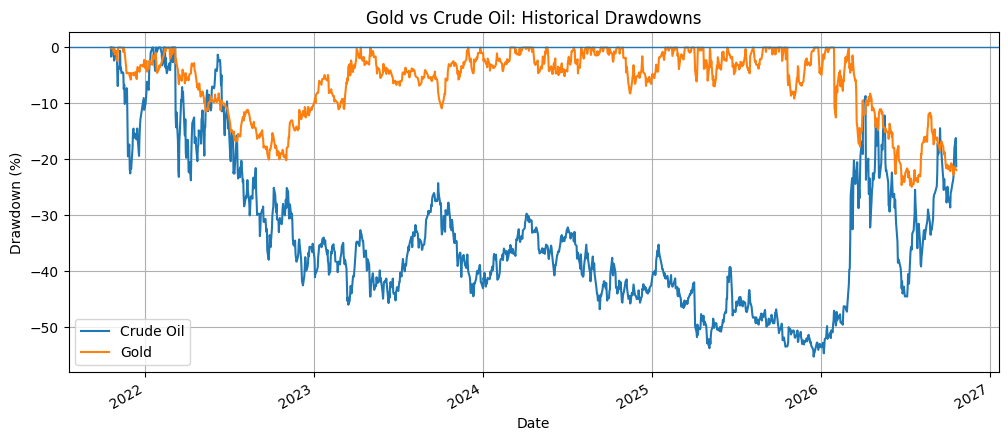

In [28]:
drawdown_pct = drawdown * 100

drawdown_pct.plot(
    figsize=(12, 5),
    title="Gold vs Crude Oil: Historical Drawdowns",
    grid=True
)

plt.ylabel("Drawdown (%)")
plt.axhline(0, linewidth=1)
plt.legend()
plt.show()

In [29]:
# Use crude oil closing prices
oil = prices["Crude Oil"].copy()

# Calculate short-term and long-term moving averages
short_ma = oil.rolling(window=20).mean()
long_ma = oil.rolling(window=50).mean()

# Trading signal: 1 = long, 0 = out of the market
signal = (short_ma > long_ma).astype(int)

# Shift signal by one day to avoid using today's close
# to pretend we traded before that close was known
position = signal.shift(1).fillna(0)

print(pd.DataFrame({
    "Price": oil,
    "20-day MA": short_ma,
    "50-day MA": long_ma,
    "Position": position
}).tail(10).round(2))

             Price  20-day MA  50-day MA  Position
Date                                              
2026-10-07   88.28      95.37      88.90       1.0
2026-10-08   91.49      94.82      89.04       1.0
2026-10-09   91.85      94.41      89.20       1.0
2026-10-12   93.74      94.03      89.38       1.0
2026-10-13   94.14      93.45      89.66       1.0
2026-10-14   95.09      93.08      90.05       1.0
2026-10-15   97.97      92.88      90.50       1.0
2026-10-16  101.41      92.94      90.98       1.0
2026-10-19  103.66      93.33      91.49       1.0
2026-10-20   97.39      93.47      91.80       1.0


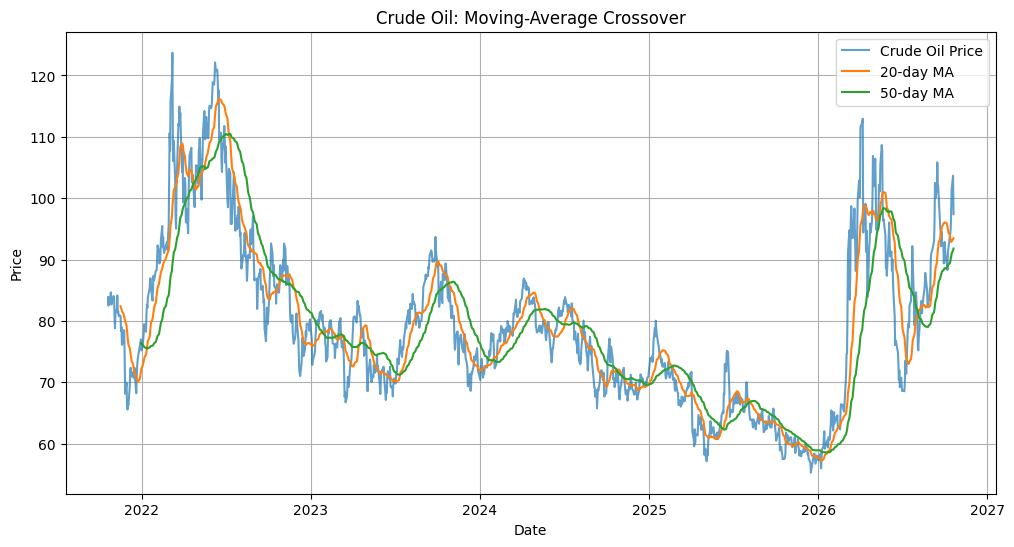

In [30]:
plt.figure(figsize=(12, 6))

plt.plot(oil.index, oil, label="Crude Oil Price", alpha=0.7)
plt.plot(oil.index, short_ma, label="20-day MA")
plt.plot(oil.index, long_ma, label="50-day MA")

plt.title("Crude Oil: Moving-Average Crossover")
plt.xlabel("Date")
plt.ylabel("Price")
plt.grid(True)
plt.legend()
plt.show()

In [31]:
# Daily crude oil returns
oil_returns = oil.pct_change().fillna(0)

# Strategy returns: hold oil only when the signal is bullish
strategy_returns = position * oil_returns

# Buy-and-hold benchmark
buy_hold_returns = oil_returns

# Assume a transaction cost of 0.05% per position change
transaction_cost = 0.0005
trades = position.diff().abs().fillna(position.abs())

strategy_returns_net = strategy_returns - trades * transaction_cost

# Cumulative growth of $1 invested
strategy_growth = (1 + strategy_returns_net).cumprod()
buy_hold_growth = (1 + buy_hold_returns).cumprod()

print("Strategy final growth:", round(strategy_growth.iloc[-1], 3))
print("Buy-and-hold final growth:", round(buy_hold_growth.iloc[-1], 3))
print("Number of position changes:", int(trades.sum()))

Strategy final growth: 1.531
Buy-and-hold final growth: 1.161
Number of position changes: 25


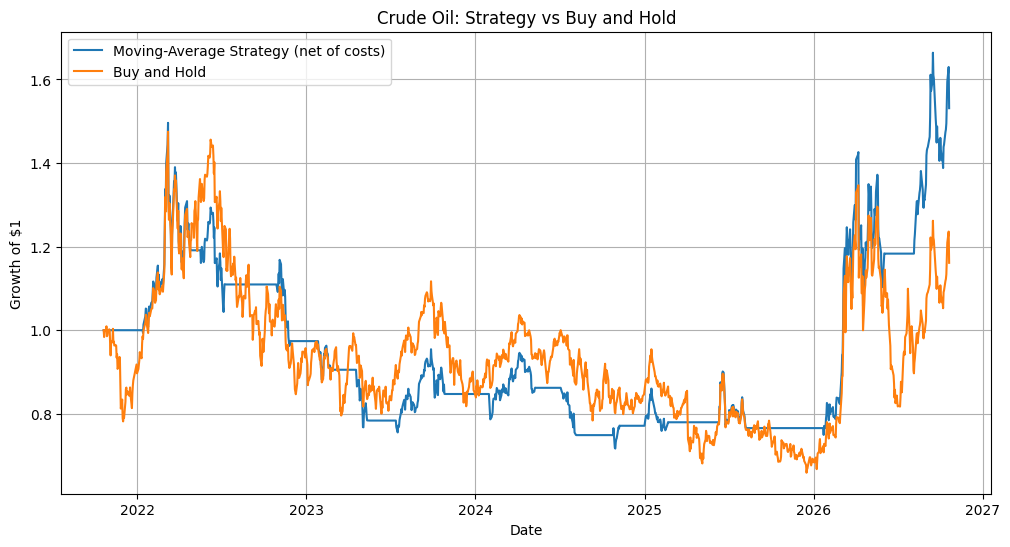

In [32]:
plt.figure(figsize=(12, 6))

plt.plot(strategy_growth, label="Moving-Average Strategy (net of costs)")
plt.plot(buy_hold_growth, label="Buy and Hold")

plt.title("Crude Oil: Strategy vs Buy and Hold")
plt.ylabel("Growth of $1")
plt.xlabel("Date")
plt.grid(True)
plt.legend()
plt.show()

In [33]:
# Annualized performance and risk metrics
trading_days = 252

years = len(strategy_returns_net) / trading_days

strategy_total_return = (
    strategy_growth.iloc[-1] - 1
) * 100

strategy_annualized_return = (
    strategy_growth.iloc[-1] ** (1 / years) - 1
) * 100

strategy_volatility = (
    strategy_returns_net.std() * np.sqrt(trading_days) * 100
)

strategy_drawdown = (
    strategy_growth / strategy_growth.cummax() - 1
)

strategy_max_drawdown = strategy_drawdown.min() * 100

print(f"Total strategy return: {strategy_total_return:.2f}%")
print(f"Annualized strategy return: {strategy_annualized_return:.2f}%")
print(f"Annualized volatility: {strategy_volatility:.2f}%")
print(f"Maximum drawdown: {strategy_max_drawdown:.2f}%")

Total strategy return: 53.12%
Annualized strategy return: 8.92%
Annualized volatility: 31.18%
Maximum drawdown: -52.09%


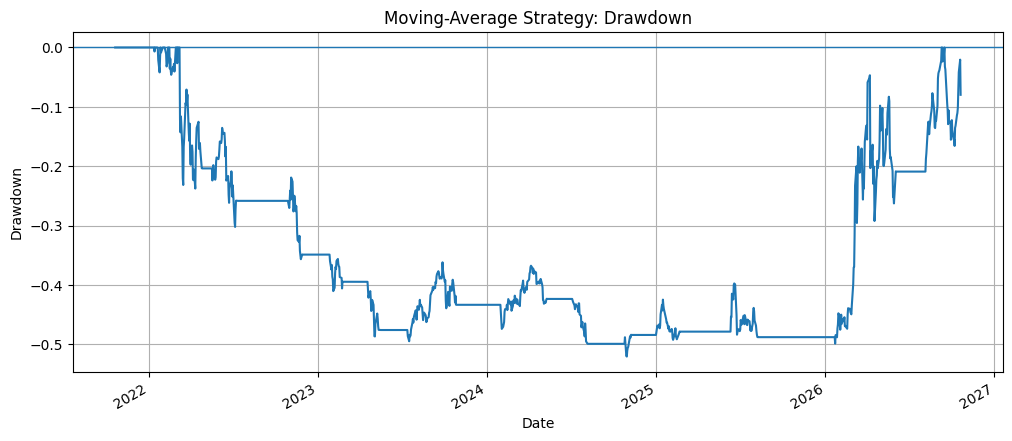

In [34]:
strategy_drawdown.plot(
    figsize=(12, 5),
    title="Moving-Average Strategy: Drawdown",
    grid=True
)

plt.ylabel("Drawdown")
plt.axhline(0, linewidth=1)
plt.show()

In [35]:
def performance_summary(daily_returns, growth):
    years = len(daily_returns) / 252

    annual_return = (growth.iloc[-1] ** (1 / years) - 1) * 100
    annual_vol = daily_returns.std() * np.sqrt(252) * 100
    max_dd = (growth / growth.cummax() - 1).min() * 100

    # Annualized Sharpe ratio, assuming a zero risk-free rate
    sharpe = (
        daily_returns.mean() / daily_returns.std()
    ) * np.sqrt(252)

    return pd.Series({
        "Total Return (%)": (growth.iloc[-1] - 1) * 100,
        "Annualized Return (%)": annual_return,
        "Annualized Volatility (%)": annual_vol,
        "Maximum Drawdown (%)": max_dd,
        "Sharpe Ratio (0% risk-free)": sharpe
    })

comparison = pd.DataFrame({
    "Moving Average Strategy": performance_summary(
        strategy_returns_net, strategy_growth
    ),
    "Buy and Hold": performance_summary(
        buy_hold_returns, buy_hold_growth
    )
})

print(comparison.round(2))

                             Moving Average Strategy  Buy and Hold
Total Return (%)                               53.12         16.12
Annualized Return (%)                           8.92          3.04
Annualized Volatility (%)                      31.18         41.60
Maximum Drawdown (%)                          -52.09        -55.32
Sharpe Ratio (0% risk-free)                     0.43          0.28


In [36]:
# Compare performance in the first and second halves
midpoint = len(strategy_returns_net) // 2

first_half = strategy_returns_net.iloc[:midpoint]
second_half = strategy_returns_net.iloc[midpoint:]

first_growth = (1 + first_half).cumprod()
second_growth = (1 + second_half).cumprod()

print("First-half return:",
      round((first_growth.iloc[-1] - 1) * 100, 2), "%")

print("Second-half return:",
      round((second_growth.iloc[-1] - 1) * 100, 2), "%")

First-half return: -9.52 %
Second-half return: 69.23 %


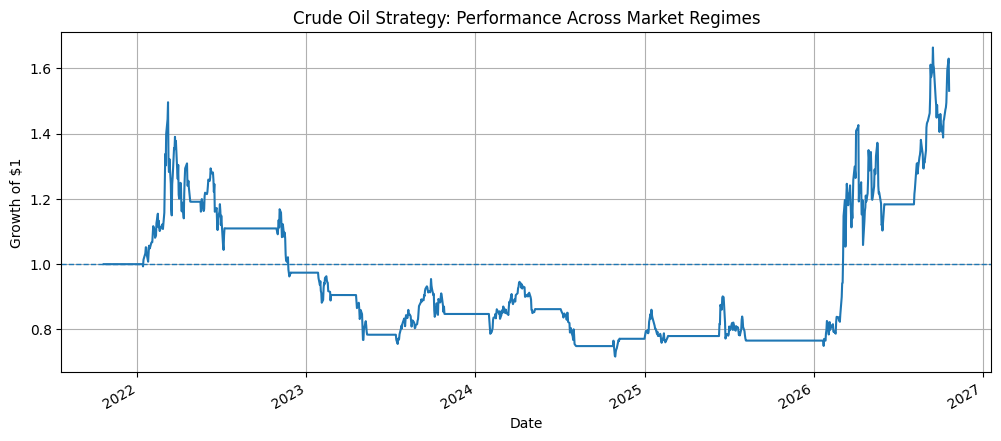

In [37]:
# Compare the strategy's cumulative performance across time
strategy_growth.plot(
    figsize=(12, 5),
    title="Crude Oil Strategy: Performance Across Market Regimes",
    grid=True
)

plt.ylabel("Growth of $1")
plt.xlabel("Date")
plt.axhline(1, linestyle="--", linewidth=1)
plt.show()

In [38]:
# Final performance comparison
final_comparison = comparison.T.copy()

final_comparison["First-Half Return (%)"] = [
    (1 + strategy_returns_net.iloc[:len(strategy_returns_net)//2]).prod().__pow__(1) * 100 - 100,
    (1 + buy_hold_returns.iloc[:len(buy_hold_returns)//2]).prod() * 100 - 100
]

final_comparison["Second-Half Return (%)"] = [
    (1 + strategy_returns_net.iloc[len(strategy_returns_net)//2:]).prod() * 100 - 100,
    (1 + buy_hold_returns.iloc[len(buy_hold_returns)//2:]).prod() * 100 - 100
]

print(final_comparison.round(2))

                         Total Return (%)  Annualized Return (%)  \
Moving Average Strategy             53.12                   8.92   
Buy and Hold                        16.12                   3.04   

                         Annualized Volatility (%)  Maximum Drawdown (%)  \
Moving Average Strategy                      31.18                -52.09   
Buy and Hold                                 41.60                -55.32   

                         Sharpe Ratio (0% risk-free)  First-Half Return (%)  \
Moving Average Strategy                         0.43                  -9.52   
Buy and Hold                                    0.28                  -0.87   

                         Second-Half Return (%)  
Moving Average Strategy                   69.23  
Buy and Hold                              17.14  


## Findings and Conclusion

Over the sample period, gold exhibited stronger annualized price appreciation and lower realized volatility than crude oil. Crude oil experienced substantially higher volatility and a deeper maximum drawdown, highlighting the different risk characteristics of the two commodity markets.

The 20-day/50-day moving-average strategy applied to crude oil generated a cumulative return of 53.29%, compared with 16.25% for the buy-and-hold benchmark under the assumptions used in this backtest. It also showed lower annualized volatility (31.17% versus 41.60%) and a slightly smaller maximum drawdown (-52.09% versus -55.32%).

However, the strategy's gains were unevenly distributed: the first half returned -9.52%, while the second half returned 69.42%. This raises questions about regime dependence and robustness. The strategy should not be considered validated without further testing on untouched data, more realistic futures contract handling, and sensitivity analysis for transaction costs and parameters.

The main takeaway is that historical returns must be evaluated alongside risk, consistency and execution assumptions. The results motivate further research but do not establish future profitability.